# Davao Transport Data Observatory — M5 Path B

**Question:** How complete, spatially consistent and interpretable are the documented transport records, and which associations require review?

The original commuter-routing concept revealed that navigation depends on reliable underlying data. M5 standardizes and evaluates that foundation. **Network X-Ray** (network exploration) and the **Route Verification Workbench** (source evidence and review decisions) are future application components; this submission does not implement them.

The analysis retains the accepted M4 OSM work, compares five completeness KPIs across two actual OSM snapshots, and analyzes a separate cleaned LTFRB baseline. DC Bus, fare and Love Bus document facts are not used in these calculations. Raw government files and detailed derived records remain private; this notebook loads only aggregate release projections.

Official criteria: [M5 checklist](https://github.com/dataengineeringpilipinas/dep-data-engineering-open-track/blob/main/docs/MILESTONE_CHECKLIST.md).

In [1]:
from pathlib import Path
import json, sys
import pandas as pd
from IPython.display import display, Markdown, Image
ROOT = Path.cwd() if (Path.cwd() / 'scripts').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
from scripts.m5_delivery import render
render()
P = ROOT / 'data/processed/m5'
segments = pd.read_csv(P / 'segmentation.csv')
history = pd.read_csv(P / 'kpi_history.csv')
quality = pd.read_csv(P / 'quality_kpis.csv')
k = json.loads((P / 'ltfrb_kpis.json').read_text())
def chart(name): display(Image(filename=str(ROOT / 'dashboard/m5_assets' / name)))
print('Inputs loaded; charts regenerated from committed aggregate data.')

Inputs loaded; charts regenerated from committed aggregate data.


## Segmentation comparisons

The primary comparison crosses mode and classification. Additional comparisons show mode by GIS status, directional metadata and metadata completeness. Geography is based on distinct slash-separated LGU text labels from either workbook direction; labels are not normalized to a gazetteer. Records may mention multiple LGUs, so geographic counts are non-additive. This is a geographic metadata proxy, not measured municipality coverage.

Each comparison retains its denominator: records for mode/status, unique source IDs for availability, layers for CRS checks, features for geometry, and populated direction slots for unresolved associations. Counts must not be interpreted as interchangeable populations.

classification,EXISTING,IRIP
mode,,
PUB,12,53
PUJ,168,25
UVE,1,26


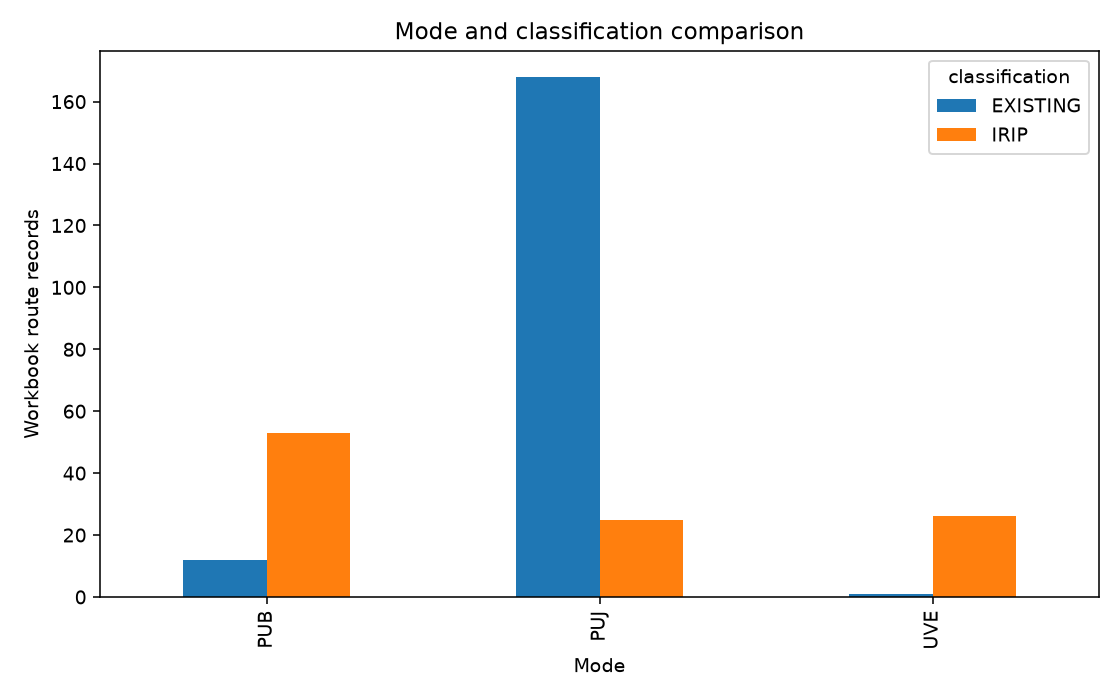

In [2]:
cross = segments[segments.dimension == 'mode x route_classification'].copy()
cross[['mode','classification']] = cross.segment.str.split(' | ', regex=False, expand=True)
display(cross.pivot(index='mode', columns='classification', values='count'))
chart('03_mode_classification.png')

PUJ dominates the inventory (193 records), mostly labelled EXISTING (168). PUB and UV Express contain larger IRIP shares: 53/65 and 26/27 respectively. Classification labels describe the source register; they do not demonstrate current services or justify treating IRIP as an active route.

,dimension,segment,count,denominator
185,mode x route_classification x GIS status,PUB | EXISTING | audited,10,285
186,mode x route_classification x GIS status,PUB | EXISTING | unrecognized_format,2,285
187,mode x route_classification x GIS status,PUB | IRIP | audited,51,285
188,mode x route_classification x GIS status,PUB | IRIP | missing_local_file,2,285
189,mode x route_classification x GIS status,PUJ | EXISTING | audited,168,285
190,mode x route_classification x GIS status,PUJ | IRIP | audited,25,285
191,mode x route_classification x GIS status,UVE | EXISTING | audited,1,285
192,mode x route_classification x GIS status,UVE | IRIP | audited,26,285
198,mode x metadata state,PUB | complete identity,65,285
199,mode x metadata state,PUJ | complete identity,193,285


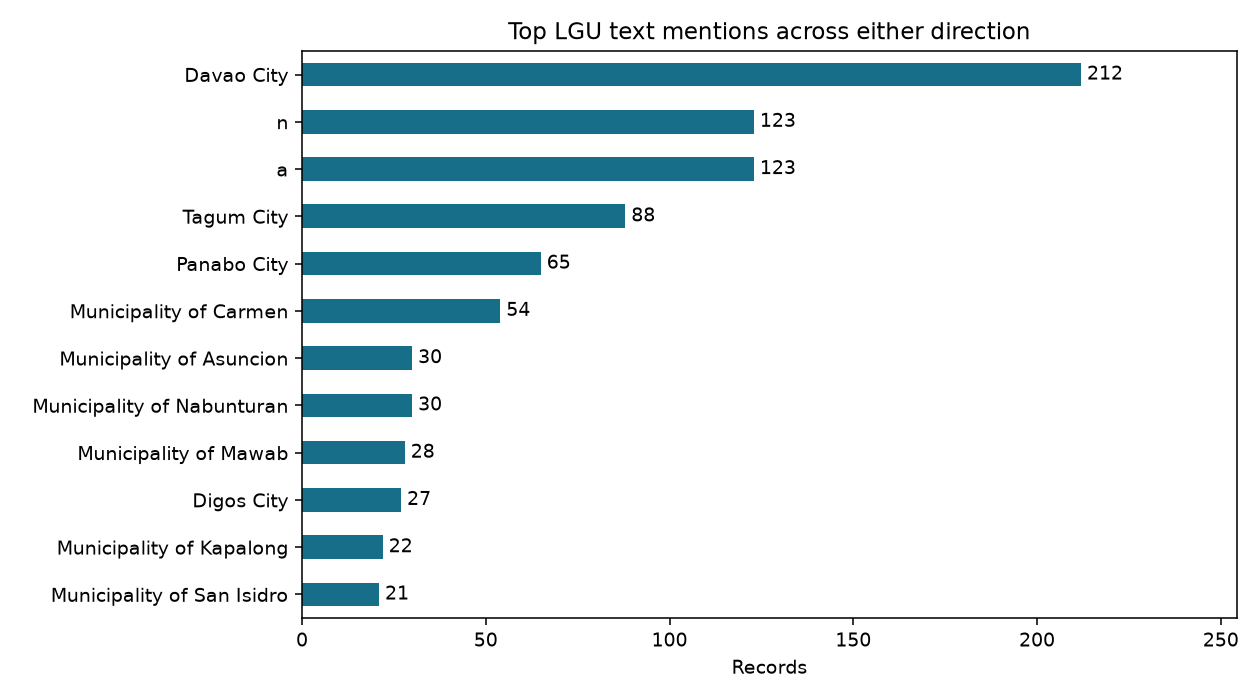

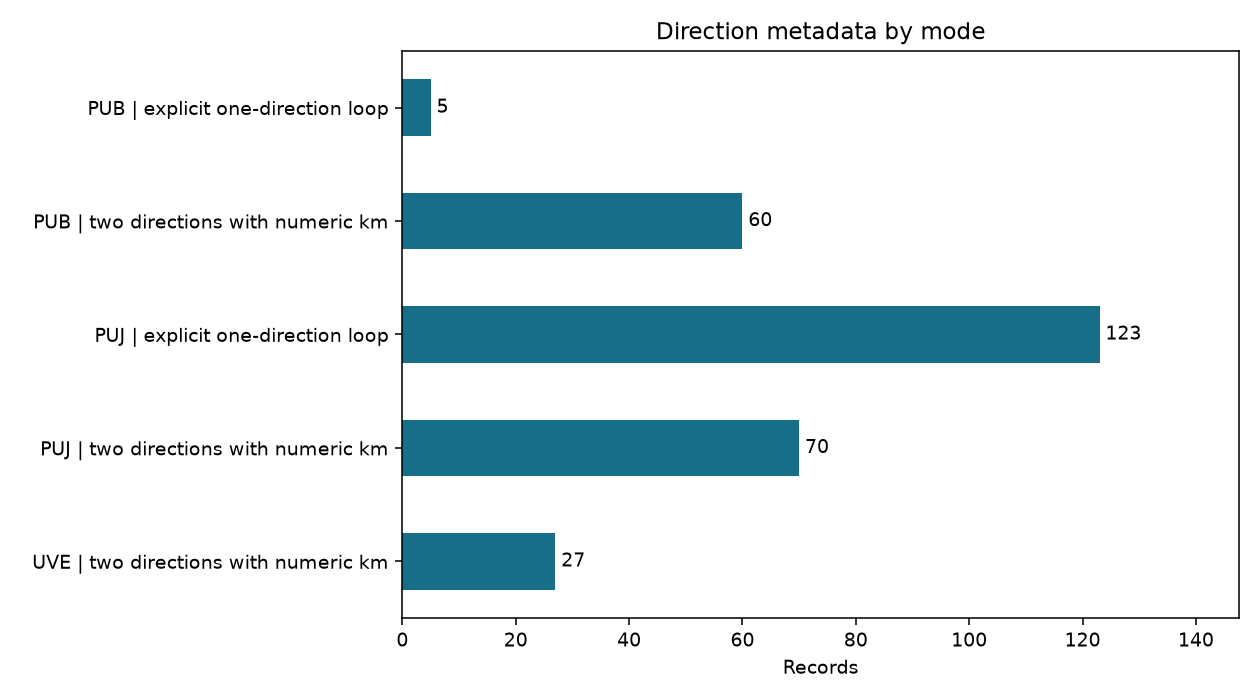

In [3]:
display(segments[segments.dimension.isin(['mode x route_classification x GIS status','mode x metadata state'])])
chart('04_geography.png')
chart('06_direction.png')

Davao City appears in many corridor labels, but the workbook includes wider Region XI and intercity routes. A line crossing a municipality cannot be established from a text mention alone. First-direction metadata is complete for all 285 records; 157 have second-direction metadata and 128 explicitly describe one-direction loops. These loops must not be penalized as missing reciprocal directions.

## Five primary KPIs and actual trend observations

Five OSM mapping-readiness KPIs have two real dated observations. These measure prerequisites for labels, locations, stop sequence and directional descriptions; they do not estimate commute time or fare. Each percentage is 100 × numerator / denominator; an empty denominator yields an undefined result. Target: 100% completeness as an analytical goal, not an official approval threshold.

The same M3 cleaning rules were applied independently to both raw snapshots, without rewriting M4 outputs. The July access date is known but its time was not retained. August's original checksum matches after Git checkout CRLF-to-LF normalization; the local-byte checksum is also recorded. Two cross-sections are insufficient to infer a long-term trend or causal change.

,kpi,title,numerator,denominator,formula,decision,target,limitations
0,named_stops,Named mapped stops,stop records with nonblank name,all mapped stop records,100 * numerator / denominator; null if denomin...,Find missing passenger-facing labels,"100% mapping completeness; analytical target, ...","Repeated cross-sections, not a fixed cohort. M..."
1,geocoded_stops,Geocoded mapped stops,stop records with latitude and longitude,all mapped stop records,100 * numerator / denominator; null if denomin...,Prioritize location verification,"100% mapping completeness; analytical target, ...","Repeated cross-sections, not a fixed cohort. M..."
2,ordered_routes,Routes with ordered stop members,route relations with at least one ordered stop...,bus/ferry route relations,100 * numerator / denominator; null if denomin...,Identify mapping gaps before graph construction,"100% mapping completeness; analytical target, ...","Repeated cross-sections, not a fixed cohort. M..."
3,origin_routes,Routes with origin metadata,route relations with nonblank from tag,bus/ferry route relations,100 * numerator / denominator; null if denomin...,Check directional metadata,"100% mapping completeness; analytical target, ...","Repeated cross-sections, not a fixed cohort. M..."
4,destination_routes,Routes with destination metadata,route relations with nonblank to tag,bus/ferry route relations,100 * numerator / denominator; null if denomin...,Check directional metadata,"100% mapping completeness; analytical target, ...","Repeated cross-sections, not a fixed cohort. M..."


,snapshot_date,kpi,numerator,denominator,value_pct,checksum_status
0,2026-07-08,named_stops,70,122,57.38,no_original_checksum
1,2026-07-08,geocoded_stops,118,122,96.72,no_original_checksum
2,2026-07-08,ordered_routes,7,14,50.00,no_original_checksum
3,2026-07-08,origin_routes,6,14,42.86,no_original_checksum
4,2026-07-08,destination_routes,6,14,42.86,no_original_checksum
5,2026-08-01,named_stops,70,122,57.38,matches_after_Git_CRLF_to_LF_normalization
6,2026-08-01,geocoded_stops,118,122,96.72,matches_after_Git_CRLF_to_LF_normalization
7,2026-08-01,ordered_routes,7,14,50.00,matches_after_Git_CRLF_to_LF_normalization
8,2026-08-01,origin_routes,6,14,42.86,matches_after_Git_CRLF_to_LF_normalization
9,2026-08-01,destination_routes,6,14,42.86,matches_after_Git_CRLF_to_LF_normalization


snapshot_date,2026-07-08,2026-08-01,change_percentage_points
kpi,,,
destination_routes,42.86,42.86,0.0
geocoded_stops,96.72,96.72,0.0
named_stops,57.38,57.38,0.0
ordered_routes,50.00,50.00,0.0
origin_routes,42.86,42.86,0.0


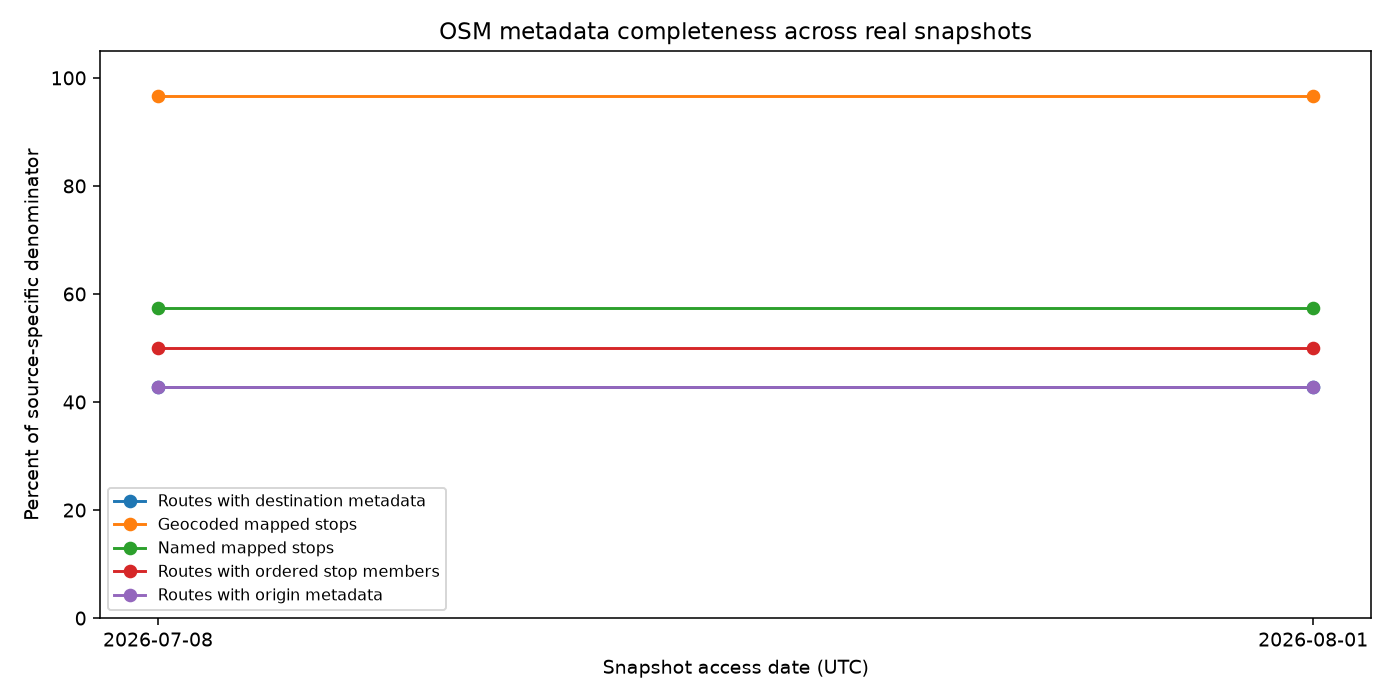

In [4]:
display(pd.read_csv(P / 'kpi_definitions.csv'))
display(history[['snapshot_date','kpi','numerator','denominator','value_pct','checksum_status']])
trend = history.pivot(index='kpi', columns='snapshot_date', values='value_pct')
trend['change_percentage_points'] = trend.iloc[:, -1] - trend.iloc[:, 0]
display(trend)
chart('09_trends.png')

All five completeness percentages are unchanged between July 8 and August 1: named stops 57.38%, geocoded stops 96.72%, routes with ordered stops 50%, origin metadata 42.86%, destination metadata 42.86%. This is evidence of stable aggregate mapping completeness in these samples, not proof that transport operations were unchanged. The largest measured gaps remain names and ordered stop metadata. LTFRB has one source baseline, so historical LTFRB change remains **not verified**; repeated audits of identical bytes do not create new transport snapshots.

## LTFRB source audit and cleaned baseline

The five primary time-series KPIs above remain OSM-only. Supplementary LTFRB quality measures assess one source baseline. Layer-level screening from the existing audit and feature-level screening from the cleaned release are shown separately; neither creates a historical trend.

For each supplementary KPI, exported definitions include the numerator, denominator, formula, grain, analytical threshold, source release and interpretation. Operational navigation readiness is not verified, not a measured zero.

,kpi,numerator,denominator,value_pct,formula,threshold,status,recalculated_pct
0,source_metadata,285.0,285,100.00,Rows with all five identity fields / workbook ...,100% target,measured,100.00
1,file_availability,264.0,266,99.25,Located recognized files / linked unique Drive...,100% target; extension does not imply valid GPKG,measured,99.25
2,successful_file_audit,262.0,266,98.50,Fully readable files / linked unique Drive IDs,100% target; readability is not geometry approval,measured,98.50
3,clean_geometry_crs,259.0,262,98.85,"Nonempty, CRS-consistent layers without null/e...",100% target; overlaps and identity assessed se...,measured,98.85
4,crs_presence,262.0,262,100.00,Layers declaring CRS / inspected layers,100% target,measured,100.00
5,length_review,0.0,118,0.00,Flagged candidate direction lengths / measured...,"Flag abs difference > max(0.5 km,10% declared km)",measured,0.00
6,unmatched_direction,324.0,442,73.30,Directions without defensible length pairing /...,Lower is better; source-file pairing is not fi...,measured,73.30
7,duplicate_link,19.0,285,6.67,Extra source-file references / workbook rows,Review only; shared sources may be intentional,measured,6.67
8,duplicate_file_bytes,0.0,264,0.00,Excess identical SHA-256 files / located linke...,Review only; checksum cannot certify authenticity,measured,0.00
9,unmatched_route_record,167.0,285,58.60,Workbook rows without any candidate directiona...,Lower is better; any paired direction does not...,measured,58.60


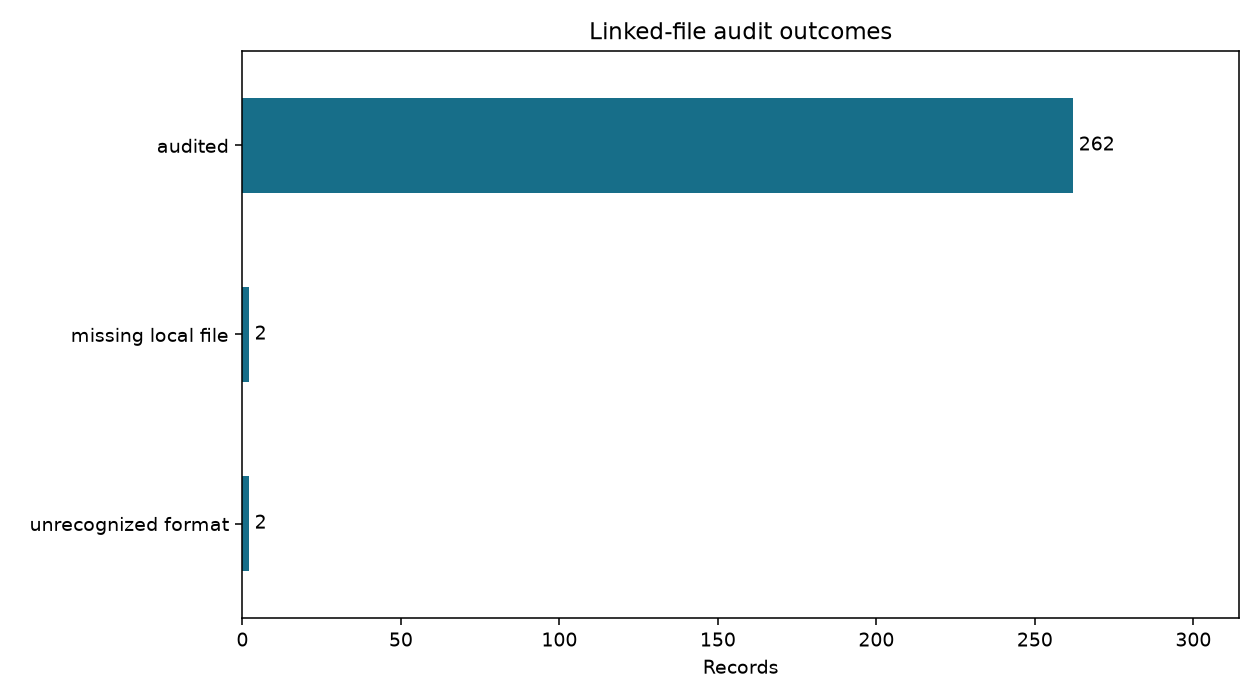

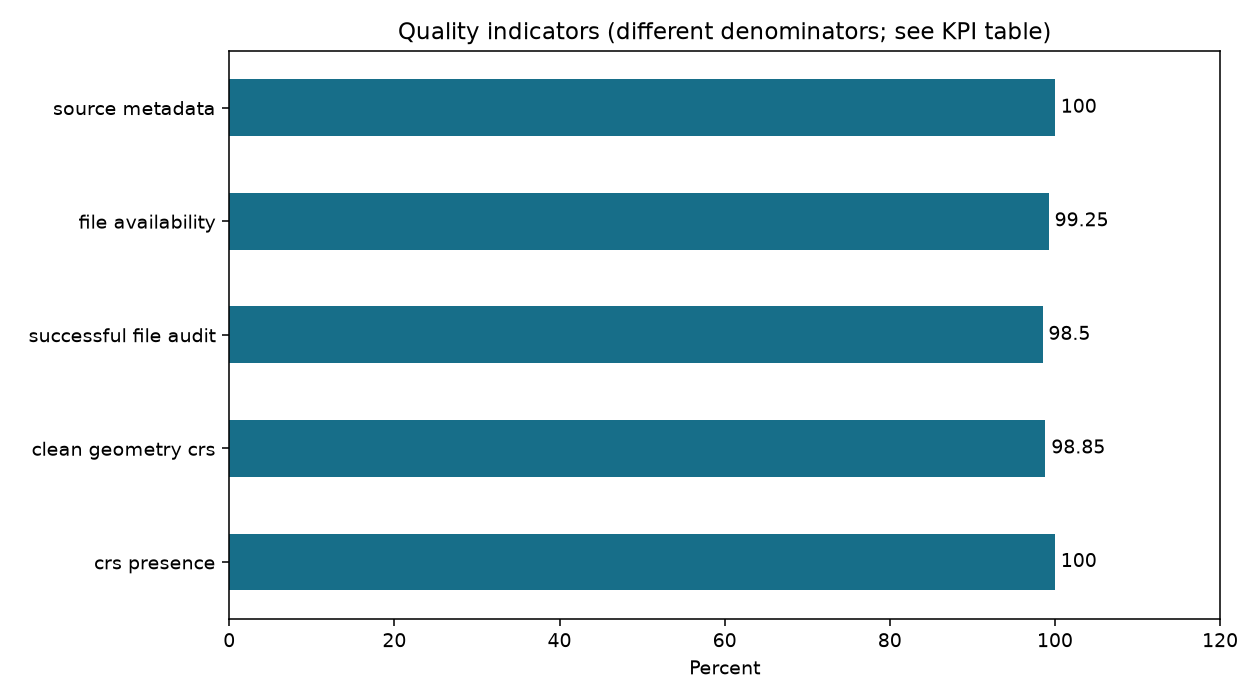

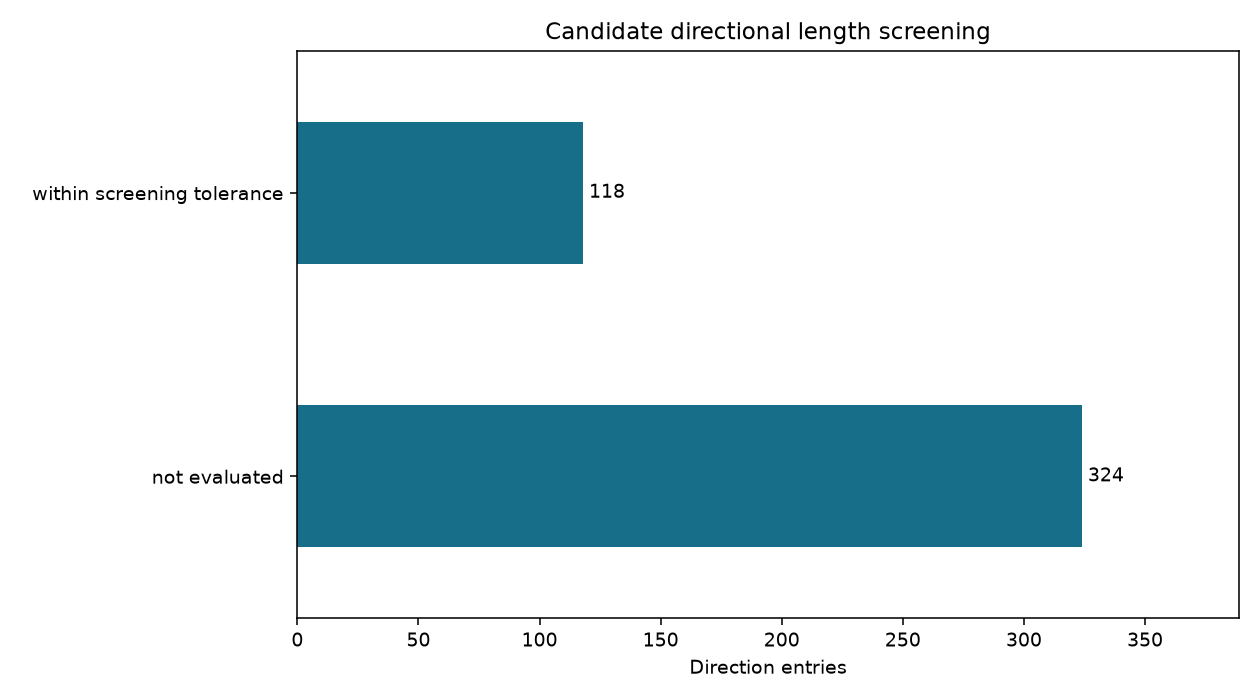

Aggregate reconciliation and unknown-navigation checks passed.


In [5]:
quality["recalculated_pct"] = (100 * quality.numerator / quality.denominator).round(2)
display(quality)
chart('05_gis_status.png')
chart('07_quality.png')
chart('08_lengths.png')
assert k['workbook_route_rows'] == 285
assert segments[segments.dimension == 'mode']['count'].sum() == k['workbook_route_rows']
assert len(history) == 10 and history.kpi.nunique() == 5
assert quality.loc[quality.kpi == 'navigation_readiness', 'status'].item() == 'not_verified'
print('Aggregate reconciliation and unknown-navigation checks passed.')

262 of 266 linked IDs completed the spatial readability audit (98.50%). In the existing layer audit, 259 of 262 layers passed basic geometry and CRS checks (98.85%). The two incomplete downloads and two shapefile bundles remain exceptions, not valid GeoPackages. Readability does not imply every feature passed.

118 of 442 populated direction slots have conservative candidate length matches; all fall within max(0.5 km, 10% declared distance). The other 324 (73.30%) remain unresolved. Zero flags among candidates cannot clear the unpaired directions or confirm actual route identity. The 128 second-direction slots on explicit one-direction loops are not applicable and are excluded from 442.

## Cleaned release integration and grains

All 285 records were retained; names, enums, directions, finite lengths and source labels were standardized without merging route identities or repairing geometry. The private release has a checksum manifest and a before/after transformation history. Only allowlisted aggregates are used here.

The 262 layers contain 266 spatial features. Of these, 263 pass structural checks and three are quarantined. Therefore **263/266 features** and **259/262 layers** describe different measurements, not a repair-driven improvement. Canonical municipality identities remain unverified; geographic figures show source-label mentions, not measured coverage, boarding access or active service.


In [6]:
cleaned = json.loads((P / 'cleaned_release_summary.json').read_text())
clean_quality = pd.read_csv(P / 'cleaned_quality_kpis.csv')
clean_segments = pd.read_csv(P / 'cleaned_segmentation.csv')
display(pd.DataFrame([
 {'grain':'Workbook route records','count':cleaned['normalized_route_records']},
 {'grain':'Linked source IDs','count':cleaned['linked_source_ids']},
 {'grain':'GIS layers','count':cleaned['spatial_layers']},
 {'grain':'Spatial features','count':sum(cleaned['feature_statuses'].values())},
 {'grain':'All direction slots','count':sum(cleaned['association_statuses'].values())},
 {'grain':'Populated direction slots (loop N/A excluded)','count':cleaned['association_statuses']['candidate']+cleaned['association_statuses']['unresolved']},
]))
measured=clean_quality[clean_quality.status == 'measured'].copy()
measured['calculated_pct']=(100*measured.numerator/measured.denominator).round(2)
assert ((measured.value_pct-measured.calculated_pct).abs()<0.001).all()
display(clean_quality[['kpi','numerator','denominator','value_pct','grain','status']])
print('Cleaned source release:',cleaned['release_version'])


,grain,count
0,Workbook route records,285
1,Linked source IDs,266
2,GIS layers,262
3,Spatial features,266
4,All direction slots,570
5,Populated direction slots (loop N/A excluded),442


,kpi,numerator,denominator,value_pct,grain,status
0,identity_fields_complete,285.0,285,100.00,workbook route records,measured
1,complete_source_file_presence,264.0,266,99.25,linked unique source IDs,measured
2,spatial_asset_inspection,262.0,266,98.50,linked unique source IDs,measured
3,consistent_layer_crs,262.0,262,100.00,spatial layers,measured
4,geometry_feature_pass,263.0,266,98.87,spatial features,measured
5,unresolved_populated_direction,324.0,442,73.30,populated source direction slots,measured
6,candidate_length_review,0.0,118,0.00,candidate direction-feature pairs,measured
7,route_review_required,171.0,285,60.00,workbook route records,measured
8,navigation_readiness,NaN,285,NaN,workbook route records,not_verified


Cleaned source release: 709ce26a035742a54735


association,candidate,not_applicable_loop,unresolved,populated_slots,unresolved_pct
mode,,,,,
PUB,1,5,124,125,99.20
PUJ,117,123,146,263,55.51
UV_EXPRESS,0,0,54,54,100.00


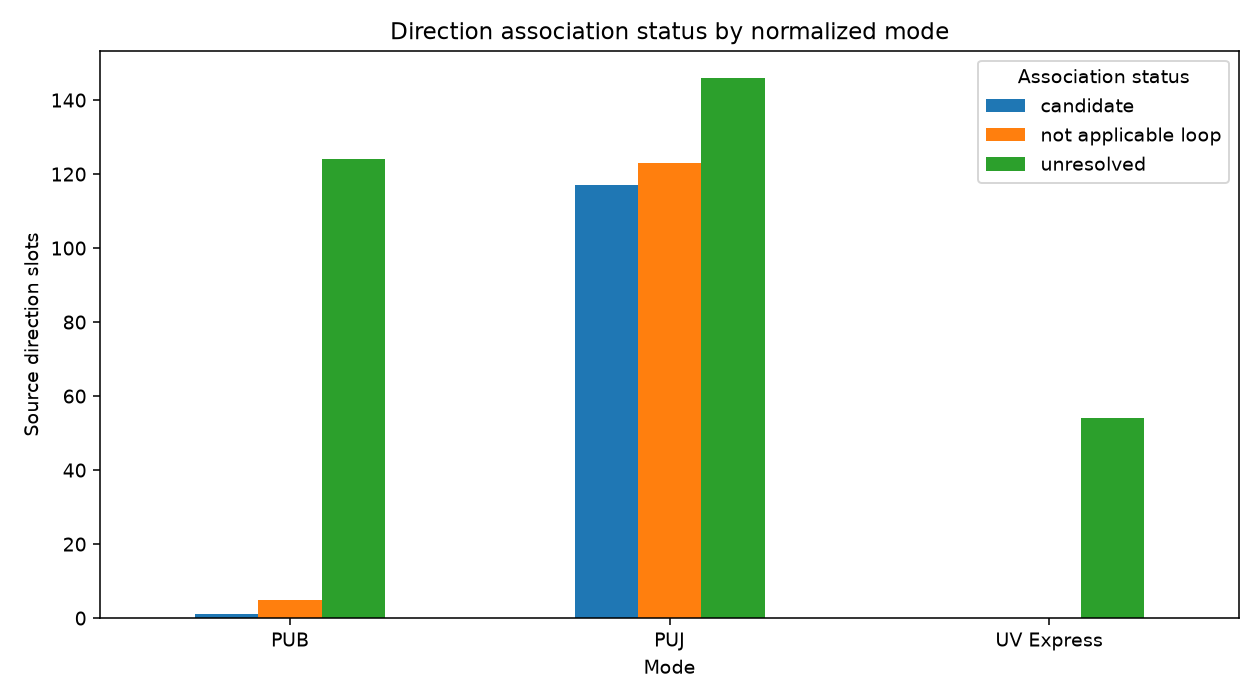

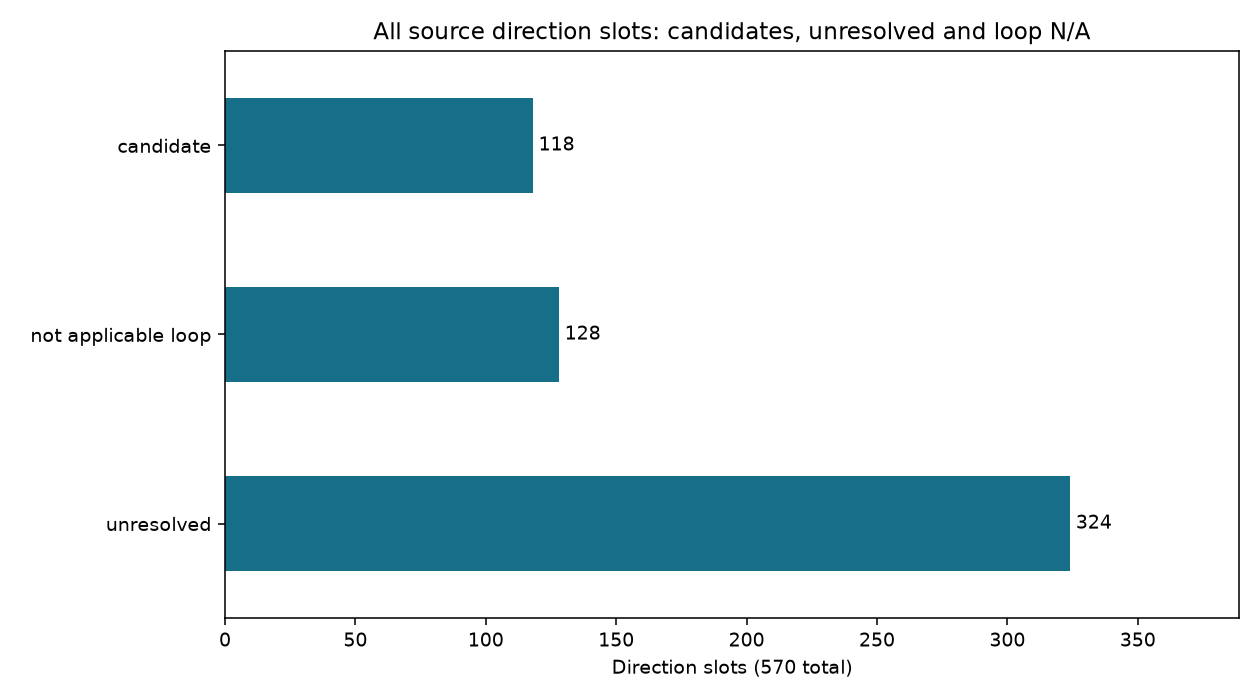

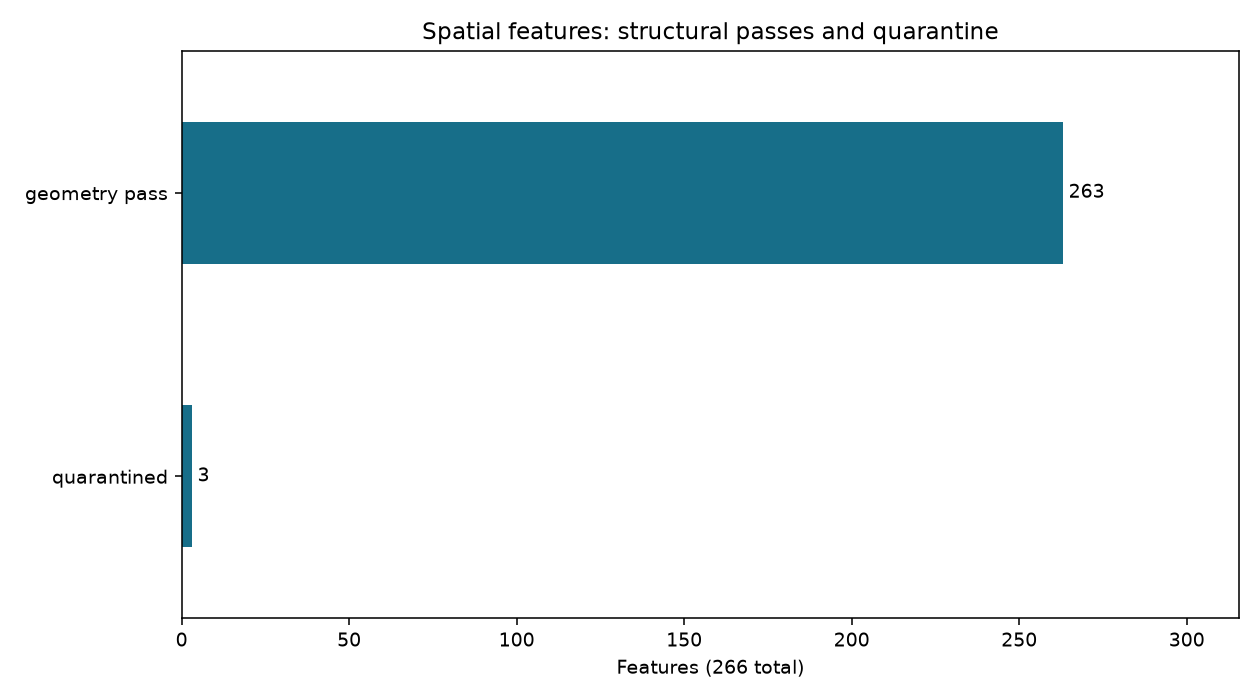

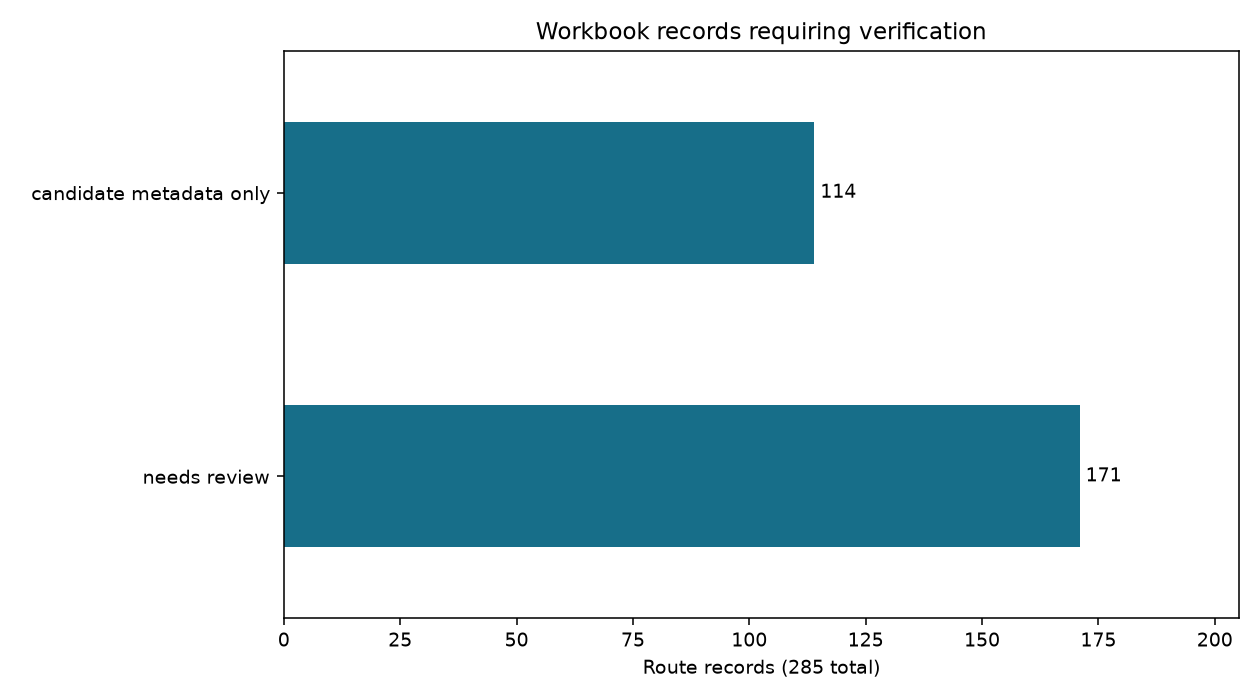

In [7]:
association_view=clean_segments[clean_segments.dimension == 'mode x association status'].copy()
association_view[['mode','association']]=association_view.segment.str.split(' | ', regex=False, expand=True)
mode_associations=association_view.pivot(index='mode',columns='association',values='count').fillna(0).astype(int)
mode_associations['populated_slots']=mode_associations['candidate']+mode_associations['unresolved']
mode_associations['unresolved_pct']=(100*mode_associations['unresolved']/mode_associations['populated_slots']).round(2)
display(mode_associations)
chart('13_mode_associations.png')
chart('10_associations.png')
chart('11_features.png')
chart('12_review.png')
assert sum(cleaned['association_statuses'].values())==2*cleaned['normalized_route_records']
assert sum(cleaned['feature_statuses'].values())==266
assert cleaned['normalized_route_records']==k['workbook_route_rows']


The comparison distinguishes mode-specific association gaps from intentional loop N/A slots. 171 records have route/direction review flags; the remaining 114 are metadata candidates, not certified operational services. These findings specify a future verification queue without implementing the application in M5.

The register contains 280 unique source names across 285 retained records. Duplicate names, shared files and exact repeated geometry are review signals, not permission to merge services. Municipality/city label conflicts and repeated labels remain unresolved until authoritative identity context is available. The transformation log records 3,248 changes in the private release, preserving source values.

Prioritize the four file exceptions, three invalid features, one exact duplicate geometry group and unresolved direction identities. Cross-route corridor overlap, confirmed transfers, fare applicability, schedules and live operations are not measured by this submission.

Candidate matching is concentrated in PUJ (117 candidates), versus one PUB candidate and no UV Express candidates. Among populated direction slots, unresolved shares are 146/263 (55.51%) for PUJ, 124/125 (99.20%) for PUB and 54/54 (100%) for UV Express. This is a comparison of automatic association evidence under conservative rules, not a ranking of service reliability or source authority. Different file/layer naming and shared-file structures may limit pairing; that explanation requires investigation rather than a causal assertion.

## One-page stakeholder brief

The following concise brief is the stakeholder deliverable; detailed methods and evidence appear above.

In [8]:
display(Markdown((ROOT / 'reports/m5/M5_STAKEHOLDER_BRIEF.md').read_text(encoding='utf-8')))

# Davao Transport Data Observatory — M5 stakeholder brief

We checked whether the Land Transportation Franchising and Regulatory Board (LTFRB) Region XI route register could be linked to the supplied map files. About 73% of the route directions we could assess still need a map line that can be linked to them with confidence. Planners can use the findings to decide which records to verify before relying on the map.

Most jeepney (PUJ) entries are listed as existing routes. Most bus and UV Express entries are marked IRIP, the register’s label for routes between provinces or regions. These labels describe how routes are recorded. Current service still needs confirmation.

Most map lines passed basic checks. Some map files were incomplete, and a few lines had errors that kept them out of the usable map files. A line that passes those checks still needs to be matched to the correct route and direction. OpenStreetMap showed no change in the completeness measures we checked between the July and August snapshots. We had a single LTFRB snapshot, so changes in the register over time remain unknown.

**Recommended next steps**

1. **LTFRB Region XI data team** should supply complete copies of the incomplete map files, review lines flagged for errors, and identify which line belongs to each route direction. This gives planners a sound basis for reviewing the network.
2. **Davao City Transport and Traffic Management Office** should check route paths and boarding points with operators on corridors under planning review. Recording the date of each check helps planners judge how current the evidence is.
3. **OpenStreetMap contributors** should update missing stop names and stop order where surveys or sources permitted for OpenStreetMap support the change. This makes routes easier to interpret and compare in future map snapshots.

The Observatory’s planned review tool can track these checks and the evidence behind each decision. The accompanying notebook and quality report contain the full counts and methods.


## Reproducibility, privacy and next stage

`python scripts/run_m5.py --execute-notebook` regenerates figures, dashboard and brief from committed aggregate inputs and executes this notebook. Private-source refresh additionally runs extraction, GIS validation, immutable cleaned-release verification and allowlisted aggregation; see docs/M5_PATH_B.md for exact commands.

The five OSM trends can be independently recalculated from committed OSM snapshots. The LTFRB detail-to-aggregate step requires the private workbook and geographic sources. Reviewers without those files can reproduce all displayed analysis from the aggregate snapshot, but cannot independently reproduce source-level GIS results; that limitation is explicit.

Raw government files, detailed cleaned records, linework, WKB, private audit reports and caches remain excluded from Git unless explicitly cleared. Only aggregate projections, code, documentation and notebook outputs are release candidates. OSM attribution: © OpenStreetMap contributors, ODbL.

M4 passed human review at 26a7f7e. M5 human acceptance and public deployment are not claimed. M6 priorities are a release-backed map/API, source evidence and durable review decisions, with authorized deployment by December 6, 2026. Those functions are outside this submission.

**Conclusion:** We standardized the transport register, measured its completeness and spatial quality, and identified the unresolved associations that the Observatory's verification workflow must address.